# La Paradoja del Cumpleaños con datos reales de nacimientos (CABA)

**Clase 27 — Teoría de Probabilidad**

En este notebook vamos a:
1. Cargar datos reales de nacimientos de la Ciudad de Buenos Aires (2018 y 2019).
2. Explorarlos con Pandas y Numpy (por mes, por día del año).
3. Visualizarlos con Matplotlib.
4. Conectar esos datos con la **Paradoja del Cumpleaños**: comparar la probabilidad teórica (asumiendo días equiprobables) contra la probabilidad empírica calculada con las fechas reales.

Fuente de datos: [Buenos Aires Data — Nacimientos](https://data.buenosaires.gob.ar/dataset/nacimientos)


## Paso 1 — Entorno y carga de datos

Cargamos las librerías y los dos datasets de nacimientos directamente desde el portal de datos abiertos de la Ciudad. Cada fila del dataset es **un nacimiento real**, con su fecha (`fecha_nacimiento`) y género (`genero_nacido`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url_2018 = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/direccion-general-de-estadisticas-y-censos/nacimientos/nacimientos_2018.csv"
url_2019 = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/direccion-general-de-estadisticas-y-censos/nacimientos/nacimientos_2019.csv"

df_2018 = pd.read_csv(url_2018, parse_dates=["fecha_nacimiento"])
df_2019 = pd.read_csv(url_2019, parse_dates=["fecha_nacimiento"])

print("Nacimientos 2018:", df_2018.shape[0])
print("Nacimientos 2019:", df_2019.shape[0])
df_2018.head()


Nacimientos 2018: 67633
Nacimientos 2019: 41217


,fecha_nacimiento,genero_nacido
0,2018-01-01,Femenino
1,2018-01-01,Masculino
2,2018-01-01,Femenino
3,2018-01-01,Femenino
4,2018-01-01,Masculino


## Paso 2 — Análisis exploratorio con Pandas y Numpy

### 2.1 — Tabla por mes

Agrupamos los nacimientos por mes para ver en qué meses nace más gente en CABA.


In [2]:
df_2018["mes"] = df_2018["fecha_nacimiento"].dt.month
df_2019["mes"] = df_2019["fecha_nacimiento"].dt.month

por_mes_2018 = df_2018.groupby("mes").size()
por_mes_2019 = df_2019.groupby("mes").size()

tabla_meses = pd.DataFrame({"2018": por_mes_2018, "2019": por_mes_2019})
print(tabla_meses)
print()
print("Mes con más nacimientos en 2018:", por_mes_2018.idxmax())
print("Mes con más nacimientos en 2019:", por_mes_2019.idxmax())


     2018    2019
mes              
1    5863  5351.0
2    5399  5004.0
3    6011  5521.0
4    5833  5379.0
5    5963  5286.0
6    5526  4990.0
7    5540  5143.0
8    5842  4543.0
9    5348     NaN
10   5623     NaN
11   5415     NaN
12   5270     NaN

Mes con más nacimientos en 2018: 3
Mes con más nacimientos en 2019: 3


### 2.2 — Tabla por día (1 a 365)

Ahora agrupamos por **día del año** (1 a 365/366) para identificar los picos más altos de nacimientos, día por día.


In [3]:
df_2018["dia_del_anio"] = df_2018["fecha_nacimiento"].dt.dayofyear
df_2019["dia_del_anio"] = df_2019["fecha_nacimiento"].dt.dayofyear

por_dia_2018 = df_2018.groupby("dia_del_anio").size()
por_dia_2019 = df_2019.groupby("dia_del_anio").size()

print("Día pico 2018:", por_dia_2018.idxmax(), "con", por_dia_2018.max(), "nacimientos")
print("Día pico 2019:", por_dia_2019.idxmax(), "con", por_dia_2019.max(), "nacimientos")
print()
print("Top 10 días con más nacimientos en 2018:")
por_dia_2018.sort_values(ascending=False).head(10)


Día pico 2018: 361 con 270 nacimientos
Día pico 2019: 65 con 256 nacimientos

Top 10 días con más nacimientos en 2018:


,0
dia_del_anio,
361,270
86,264
85,263
94,259
281,257
87,253
233,250
45,250
149,249


### 2.3 — Coincidencias de cumpleaños

Como cada dataset es la **población completa** de nacimientos de un año (no una muestra de N personas), contar coincidencias directamente sobre todo el dataset es trivial: todos los días ya tienen decenas de nacimientos, así que "coinciden" por construcción.

Lo que sí reproduce la lógica de la Paradoja del Cumpleaños es usar esas fechas reales (mes-día, sin el año) como **población de origen** para simular grupos de tamaño *n*, y calcular con qué frecuencia dos personas del grupo comparten fecha.


In [4]:
# Nos quedamos con el mes-día de cada nacimiento (ignorando el año), y juntamos ambos datasets
fechas_2018 = df_2018["fecha_nacimiento"].dt.strftime("%m-%d")
fechas_2019 = df_2019["fecha_nacimiento"].dt.strftime("%m-%d")
poblacion_fechas = pd.concat([fechas_2018, fechas_2019]).values

rng = np.random.default_rng(42)

def prob_empirica(n_personas, n_sim=2000):
    """Probabilidad de al menos una coincidencia, muestreando fechas REALES."""
    coincidencias = 0
    for _ in range(n_sim):
        muestra = rng.choice(poblacion_fechas, size=n_personas, replace=False)
        if len(muestra) != len(set(muestra)):
            coincidencias += 1
    return coincidencias / n_sim


## De los datos a la teoría — La fórmula matemática

La probabilidad de que **n personas NO cumplan años el mismo día** (asumiendo un año de 365 días equiprobables) es la siguiente productoria:

$$P(\text{todos diferentes}) = \prod_{i=0}^{n-1}\frac{365-i}{365}$$

Expandida, se ve así:

$$P(\text{todos diferentes})=\frac{365}{365}\times \frac{364}{365}\times \frac{363}{365}\times \dots \times \frac{365-(n-1)}{365}$$

**De la fórmula al código:** cada vuelta de un `for` multiplica un factor de la productoria. Cuando `i=0` el factor es `365/365`, cuando `i=1` es `364/365`, y así hasta `(365-(n-1))/365`. Al final se le resta a 1 porque la fórmula da la probabilidad de que **nadie** coincida, y la paradoja pregunta por la probabilidad de que **al menos dos sí** coincidan.


In [5]:
def prob_teorica(n_personas, dias=365):
    p = 1.0
    for i in range(n_personas):
        p *= (dias - i) / dias   # esto ES la productoria, término a término
    return 1 - p                  # la paradoja pide P(al menos una coincidencia)

def prob_uniforme_simulada(n_personas, n_sim=2000):
    """Simulación bajo el supuesto ideal: días equiprobables (1/365).
    Sirve para validar que el código de simulación reproduce bien la fórmula."""
    coincidencias = 0
    for _ in range(n_sim):
        muestra = rng.integers(1, 366, size=n_personas)  # días uniformes al azar
        if len(muestra) != len(np.unique(muestra)):
            coincidencias += 1
    return coincidencias / n_sim


### Armando la tabla comparativa

Ahora calculamos las tres probabilidades para distintos tamaños de grupo:

- **`prob_teorica`**: la fórmula matemática de arriba, asumiendo 365 días equiprobables (el ideal 1/365).
- **`prob_uniforme_simulada`**: simulación con fechas uniformes al azar — debería coincidir casi exacto con `prob_teorica`, y sirve para validar que la simulación está bien armada.
- **`prob_empirica`**: simulación usando las fechas **reales** de nacimientos de CABA (con toda su estacionalidad y sus picos/valles).


In [6]:
tamanios = [5, 10, 15, 20, 23, 30, 40, 50, 70]

resultados = pd.DataFrame({
    "n_personas": tamanios,
    "prob_teorica": [prob_teorica(n) for n in tamanios],
    "prob_uniforme_simulada": [prob_uniforme_simulada(n) for n in tamanios],
    "prob_empirica": [prob_empirica(n) for n in tamanios],
})
resultados


,n_personas,prob_teorica,prob_uniforme_simulada,prob_empirica
0,5,0.027136,0.0230,0.0325
1,10,0.116948,0.1220,0.1340
2,15,0.252901,0.2640,0.2655
3,20,0.411438,0.4160,0.4560
4,23,0.507297,0.5085,0.5525
5,30,0.706316,0.6840,0.7580
6,40,0.891232,0.8945,0.9070
7,50,0.970374,0.9650,0.9815
8,70,0.999160,1.0000,0.9995


## Paso 3 — Visualización de datos con Matplotlib

### Nacimientos por día del año, 2018 vs 2019


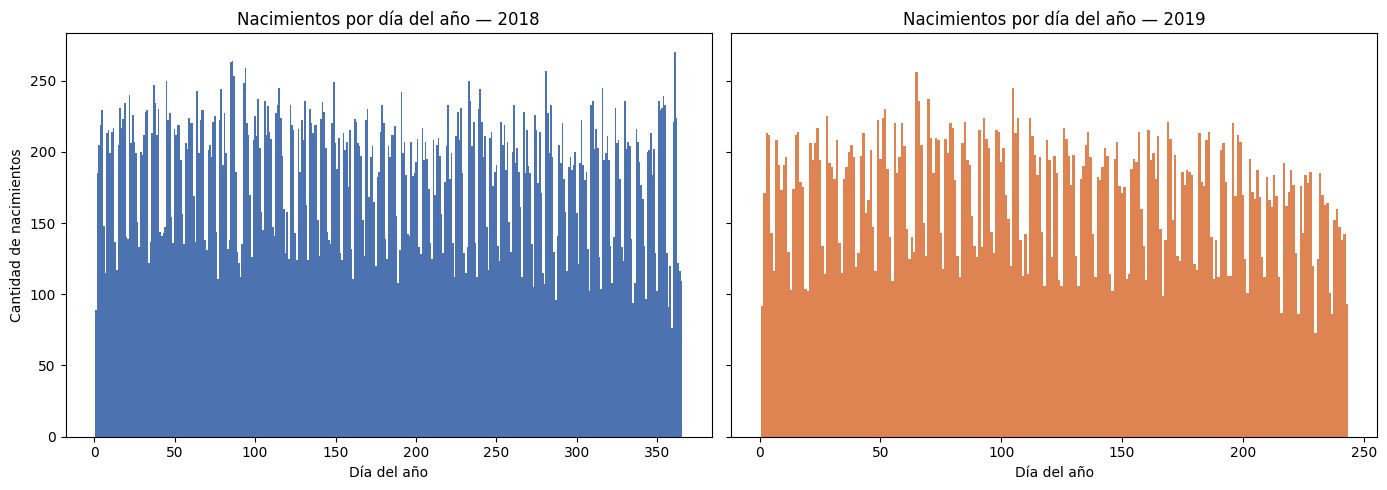

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].bar(por_dia_2018.index, por_dia_2018.values, width=1, color="#4C72B0")
axes[0].set_title("Nacimientos por día del año — 2018")
axes[0].set_xlabel("Día del año")
axes[0].set_ylabel("Cantidad de nacimientos")

axes[1].bar(por_dia_2019.index, por_dia_2019.values, width=1, color="#DD8452")
axes[1].set_title("Nacimientos por día del año — 2019")
axes[1].set_xlabel("Día del año")

plt.tight_layout()
plt.show()


### Media y desvío estándar de nacimientos diarios, por mes

Este es el gráfico que resuelve la pregunta original: en vez de comparar día por día contra 1/365 (donde el ruido de muestreo hace parecer todo "desviado"), agregamos por mes y mostramos la media diaria de nacimientos ± su desvío estándar. Esto reduce el ruido y deja ver mejor la estacionalidad real.


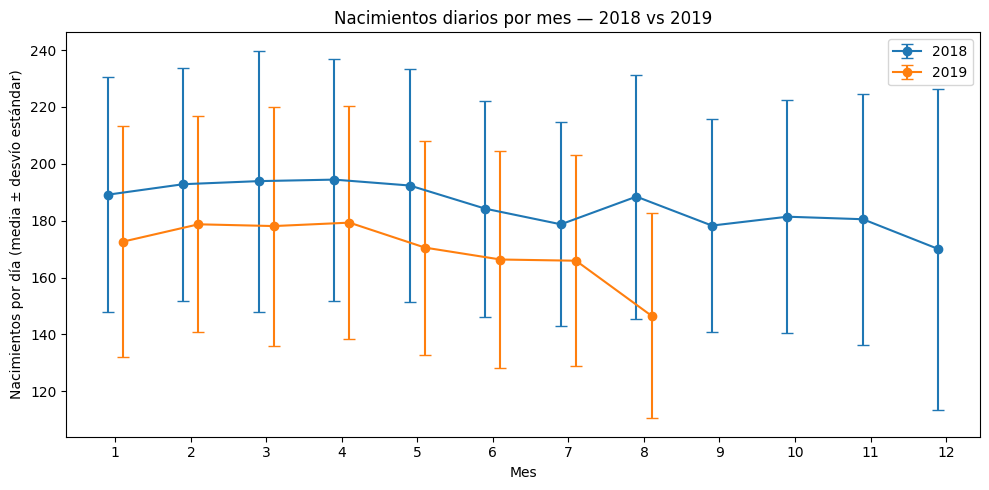

In [9]:
def resumen_mensual(df):
    conteo_diario = df.groupby(df["fecha_nacimiento"].dt.date).size()
    conteo_diario.index = pd.to_datetime(conteo_diario.index)
    return conteo_diario.groupby(conteo_diario.index.month).agg(media="mean", std="std")

resumen_2018 = resumen_mensual(df_2018)
resumen_2019 = resumen_mensual(df_2019)

fig, ax = plt.subplots(figsize=(10, 5))
# Usamos el índice respectivo de cada año para evitar el error de tamaños
meses_2018 = resumen_2018.index
meses_2019 = resumen_2019.index

ax.errorbar(meses_2018 - 0.1, resumen_2018["media"], yerr=resumen_2018["std"], fmt="o-", capsize=4, label="2018")
ax.errorbar(meses_2019 + 0.1, resumen_2019["media"], yerr=resumen_2019["std"], fmt="o-", capsize=4, label="2019")

ax.set_xticks(range(1, 13))
ax.set_xlabel("Mes")
ax.set_ylabel("Nacimientos por día (media ± desvío estándar)")
ax.set_title("Nacimientos diarios por mes — 2018 vs 2019")
ax.legend()
plt.tight_layout()
plt.show()

### Teórica vs. empírica: la curva de la Paradoja del Cumpleaños

Graficamos las tres curvas de `resultados` juntas para ver visualmente cómo se comparan.


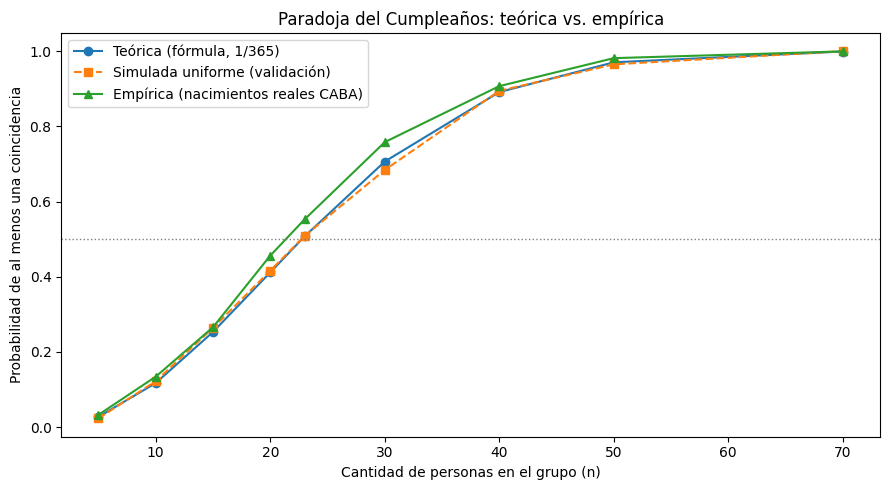

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(resultados["n_personas"], resultados["prob_teorica"], "o-", label="Teórica (fórmula, 1/365)")
ax.plot(resultados["n_personas"], resultados["prob_uniforme_simulada"], "s--", label="Simulada uniforme (validación)")
ax.plot(resultados["n_personas"], resultados["prob_empirica"], "^-", label="Empírica (nacimientos reales CABA)")
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax.set_xlabel("Cantidad de personas en el grupo (n)")
ax.set_ylabel("Probabilidad de al menos una coincidencia")
ax.set_title("Paradoja del Cumpleaños: teórica vs. empírica")
ax.legend()
plt.tight_layout()
plt.show()


## Interpretación de los resultados

- **`prob_teorica` ≈ `prob_uniforme_simulada`**: esto confirma que el código de simulación está bien armado. Con 2000 simulaciones, la ley de los grandes números hace que la frecuencia relativa converja al valor exacto de la fórmula.

- **`prob_empirica` vs. las otras dos**: la diferencia aísla el efecto de que los nacimientos reales **no son uniformes** (hay estacionalidad a lo largo del año, y menos partos programados los fines de semana). Cuando una distribución se aleja de la uniformidad, la probabilidad de coincidencia **aumenta** respecto al caso ideal — es un resultado general: cualquier desvío de la uniformidad hace las colisiones más probables, nunca menos.

- Por eso se espera ver `prob_empirica` levemente por encima de `prob_teorica`, sobre todo en tamaños de grupo intermedios (15 a 30 personas aprox.), que es donde la curva todavía no está saturada cerca de 1.

**Conclusión:** la teoría asume equiprobabilidad (1/365 para cada día), pero los datos reales de CABA muestran que romper esa uniformidad no arruina la paradoja — si acaso, la refuerza un poco.


## Paso 4 — De los datos a la teoría probabilística

**Espacio muestral (Ω):** conjunto de todas las fechas posibles de nacimiento en CABA para el año dado (365 o 366 resultados posibles).

**Sucesos (ℱ):** ejemplos de eventos definidos sobre Ω:
- "Nacer un día de fin de semana"
- "El mes de nacimiento es enero"
- "Dos personas de un grupo de tamaño *n* comparten la misma fecha de nacimiento" (el evento central de la Paradoja del Cumpleaños)

**Probabilidades (P):** comparamos:
- La probabilidad teórica de nacer un día específico bajo el supuesto de uniformidad: 1/365 ≈ 0,27%.
- La frecuencia relativa real de cada día: `por_dia_2018 / por_dia_2018.sum()`.
- La probabilidad de coincidencia en un grupo de *n* personas: `resultados["prob_teorica"]` (ideal) vs. `resultados["prob_empirica"]` (real), tal como se ve en el gráfico y la interpretación de arriba.
